Ekstraksi PDF & Pembuatan Vektor

In [1]:
# 1. Instalasi seluruh pustaka dalam satu eksekusi
!pip install -qU langchain langchain-community langchain-core langchain-google-genai langchain-huggingface langchain-chroma pypdf chromadb sentence-transformers tenacity

import os
from glob import glob
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

# 2. Memuat semua dokumen PDF dari direktori
pdf_directory = "/content/drive/MyDrive/RAG/Jurnal"
pdf_files = glob(os.path.join(pdf_directory, "*.pdf"))
print(f"Ditemukan {len(pdf_files)} file PDF di {pdf_directory}")

documents = []
for file_path in pdf_files:
    try:
        loader = PyPDFLoader(file_path)
        docs = loader.load()
        documents.extend(docs)
        print(f"Berhasil memuat: {os.path.basename(file_path)} ({len(docs)} halaman)")
    except Exception as e:
        print(f"Gagal memuat {os.path.basename(file_path)}: {e}")

print(f"Total halaman dari seluruh dokumen: {len(documents)}")

# 3. Memecah dokumen menjadi chunks (parameter 'separators' agar lebih aman)
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
    length_function=len,
    separators=["\n\n", "\n", ".", " ", ""],
    is_separator_regex=False,
)
chunks = text_splitter.split_documents(documents)
print(f"Total chunks yang dihasilkan: {len(chunks)}")

# 4. Inisialisasi Embeddings dan pembuatan Vector Database
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
persist_directory = "/content/drive/MyDrive/chroma_db"

vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embeddings,
    persist_directory=persist_directory
)
print(f"✅ Vector database Chroma berhasil dibuat dan disimpan di: {persist_directory}")

/tmp/ipykernel_10859/2636957984.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


Ditemukan 14 file PDF di /content/drive/MyDrive/RAG/Jurnal
Berhasil memuat: Real-Time RAG for the Identification of Supply Chain Vulnerabilities.pdf (14 halaman)
Berhasil memuat: Application of retrieval-augmented generation for interactive industrial knowledge management via a large language model.pdf (13 halaman)
Berhasil memuat: Knowledge Graph-Guided Retrieval-Augmented Generation for Explainable Supply Chain Resilience Assessment.pdf (6 halaman)
Berhasil memuat: Large language models in manufacturing a comprehensive review.pdf (27 halaman)
Berhasil memuat: Enhancing-Supply-Chain-Efficiency-Through-Retrieve-Augmented-Generation-Approach-in Large Language Models.pdf (5 halaman)
Berhasil memuat: Runtime Prediction for Local Deployment of Large LanguageModels A Case Study on Qwen Models Covering LoRAFine-Tuning, RAG, and Inference.pdf (9 halaman)
Berhasil memuat: A Multi-Agent Framework for Multi-Source Manufacturing Knowledge Integration and Question Answering.pdf (9 halaman)
Berhasi

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✅ Vector database Chroma berhasil dibuat dan disimpan di: /content/drive/MyDrive/chroma_db


Akses Google Drive & API

In [2]:
from google.colab import drive
import os
from google.colab import userdata

# 1. Hubungkan (Mount) Google Drive
print("Meminta akses ke Google Drive...")
drive.mount('/content/drive')

# 2. Mengambil API Key otomatis dari fitur Secrets (Kunci) Colab
print("Memuat Google API Key...")
os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')

print("✅ Akses Drive dan API Key berhasil dimuat!")

Meminta akses ke Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Memuat Google API Key...
✅ Akses Drive dan API Key berhasil dimuat!


Pembuatan GAP Matrix

In [3]:
import os
import json
import pandas as pd
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import JsonOutputParser
from tenacity import retry, wait_exponential, stop_after_attempt

# 1. INISIALISASI LLM
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0.1
)

# 2. AKSES DATABASE CHROMA
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
persist_directory = "/content/drive/MyDrive/chroma_db"
vectorstore = Chroma(persist_directory=persist_directory, embedding_function=embeddings)

all_data = vectorstore.get(include=["metadatas", "documents"])
unique_sources = set([meta['source'] for meta in all_data['metadatas']])
print(f"Ditemukan {len(unique_sources)} jurnal unik di dalam database.\n")

# 3. PROMPT TEMPLATE DENGAN OUTOUT PARSER KHUSUS JSON
prompt = PromptTemplate.from_template(
    """Anda adalah asisten peneliti tingkat Magister.
Analisis teks dari SATU dokumen jurnal di bawah ini.
Jika informasi tidak ditemukan, WAJIB tulis "Tidak disebutkan".
JANGAN mengarang informasi (halusinasi).

Kunci JSON:
- "Judul"
- "DOI"
- "Penulis"
- "Tahun"
- "Problem"
- "Metodologi"
- "Dataset"
- "Temuan"
- "Keterbatasan_Penelitian"
- "Future_Work"

Konteks Jurnal:
{context}"""
)

# 4. PIPA EKSTRAKSI MENGGUNAKAN JsonOutputParser BAWAAN LangChain
extraction_chain = prompt | llm | JsonOutputParser()
hasil_semua_jurnal = []

# 5. FUNGSI EKSTRAKSI DENGAN AUTO-RETRY (EXPONENTIAL BACKOFF)
# Jika API terkena limit (Error 429), sistem akan menunggu 4 detik, lalu 8, lalu 16 dst, maksimal 5 kali percobaan.
@retry(wait=wait_exponential(multiplier=1, min=4, max=60), stop=stop_after_attempt(5))
def extract_with_retry(text_context):
    return extraction_chain.invoke({"context": text_context})

# 6. PROSES ITERASI
for source in unique_sources:
    nama_file = os.path.basename(source)
    print(f"Memproses: {nama_file}...")

    # Ambil SEMUA chunks yang HANYA berasal dari jurnal ini
    chunks_jurnal_ini = [
        doc for doc, meta in zip(all_data['documents'], all_data['metadatas'])
        if meta['source'] == source
    ]

    # Gabungkan semua chunks
    teks_konteks = "\n\n".join(chunks_jurnal_ini)

    try:
        # Langsung proses, tidak perlu time.sleep manual
        data_json = extract_with_retry(teks_konteks)
        data_json["File_Sumber"] = nama_file
        hasil_semua_jurnal.append(data_json)
        print(f"✅ Sukses diekstrak: {nama_file}")
    except Exception as e:
        print(f"❌ Gagal memproses {nama_file} setelah 5x percobaan: {e}")

# 7. KONVERSI KE TABEL (PANDAS DATAFRAME)
print("\n====================================")
print("=== LITERATURE GAP MATRIX SELESAI ===")
print("====================================\n")

df_gap_matrix = pd.DataFrame(hasil_semua_jurnal)

if not df_gap_matrix.empty:
    cols = ['File_Sumber'] + [col for col in df_gap_matrix.columns if col != 'File_Sumber']
    df_gap_matrix = df_gap_matrix[cols]

    display(df_gap_matrix)
    df_gap_matrix.to_excel("/content/drive/MyDrive/GAP_Matrix_Result.xlsx", index=False)
    df_gap_matrix.to_csv("/content/drive/MyDrive/GAP_Matrix_Result.csv", index=False)
    print("File GAP_Matrix_Result.xlsx dan .csv berhasil disimpan!")
else:
    print("Tidak ada data yang berhasil diekstrak.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Ditemukan 14 jurnal unik di dalam database.

Memproses: Large language models in manufacturing a comprehensive review.pdf...
✅ Sukses diekstrak: Large language models in manufacturing a comprehensive review.pdf
Memproses: LLM-Stochastic Optimization Framework Intelligent SupplyChain Planning with Uncertainty-Aware Inventory Control.pdf...
✅ Sukses diekstrak: LLM-Stochastic Optimization Framework Intelligent SupplyChain Planning with Uncertainty-Aware Inventory Control.pdf
Memproses: Enhancing retrieval-augmented generation for interoperable industrial knowledge representation and inference toward cognitive digital twins.pdf...
✅ Sukses diekstrak: Enhancing retrieval-augmented generation for interoperable industrial knowledge representation and inference toward cognitive digital twins.pdf
Memproses: Real-Time RAG for the Identification of Supply Chain Vulnerabilities.pdf...
✅ Sukses diekstrak: Real-Time RAG for the Identification of Supply Chain Vulnerabilities.pdf
Memproses: A Multi-Ag

,File_Sumber,Judul,DOI,Penulis,Tahun,Problem,Metodologi,Dataset,Temuan,Keterbatasan_Penelitian,Future_Work
0,Large language models in manufacturing a compr...,Large language models in manufacturing: a comp...,10.1007/s00170-026-18711-4,"[Mazdak Maghanaki, Mohammad Shahin, F. Frank C...",2026,Sistem pembelajaran mesin tradisional dan sist...,Tinjauan pustaka sistematis (Systematic Litera...,Tidak ada dataset baru yang dibuat dalam penel...,LLM berhasil mengubah sistem manufaktur dari a...,Aplikasi LLM dalam manufaktur menghadapi beber...,Rekomendasi pengembangan meliputi: (1) Penerap...
1,LLM-Stochastic Optimization Framework Intellig...,LLM-Stochastic Optimization Framework: Intelli...,https://doi.org/10.1145/3813822.3813966,"Sihua Zhou, Xing Zhou",2026,1) Ketidakmampuan metode yang ada dalam mengin...,1) Pengembangan kerangka kerja LLM-SIO (LLM-St...,Dataset rantai pasok multi-produk riil dari pe...,1) Kerangka kerja LLM-SIO mencapai tingkat lay...,Tidak disebutkan,1) Memperluas kerangka kerja ke jaringan ranta...
2,Enhancing retrieval-augmented generation for i...,Enhancing retrieval-augmented generation for i...,https://doi.org/10.1016/j.compind.2025.104330,"Dachuan Shi, Jianzhang Li, Olga Meyer, Thomas ...",2025,Pendekatan tradisional untuk representasi dan ...,1. Menggunakan Asset Administration Shell (AAS...,Dataset evaluasi statistik retrival disusun me...,1. RAG yang ditingkatkan mencapai nilai Faktua...,1. Implementasi RAG saat ini hanya mengodekan ...,1. Memperluas kapabilitas sistem RAG agar mamp...
3,Real-Time RAG for the Identification of Supply...,Real-Time RAG for the Identification of Supply...,Tidak disebutkan,"[Jesse Ponnock, Grace Kenneally, Michael Rober...",2025,Model Bahasa Besar (LLM) memiliki basis penget...,Peneliti mengusulkan pendekatan pemrosesan RAG...,"Dokumen pelaporan keuangan SEC (10-K, 10-Q, 8-...",[Fine-tuning pada model embedding/retriever se...,[Penelitian menggunakan model LLM berukuran ke...,[Mengoptimalkan kemampuan sistem untuk mengeks...
4,A Multi-Agent Framework for Multi-Source Manuf...,A Multi-Agent Framework for Multi-Source Manuf...,10.1145/3701716.3716884,"Teng Mao, Shuangtao Yang, Bo Fu",2025,Kesulitan dalam mengelola dan memanfaatkan pen...,Kerangka kerja Multi-Agent berbasis Retrieval-...,Dataset pengetahuan manufaktur multi-sumber se...,Integrasi Multi-Agent dan Thinking RAG berhasi...,Tidak disebutkan,Fokus pada validasi eksperimental lebih lanjut...
5,Runtime Prediction for Local Deployment of Lar...,Runtime Prediction for Local Deployment of Lar...,10.1145/3784828.3785338,"[Jian Guo, Jianwen Wei, Yufei Cheng, Jiajie Sh...",2026,Tingginya tuntutan komputasi dan perilaku runt...,Eksperimentasi terkontrol pada kluster multi-G...,"1. Subset dari Stanford Alpaca dataset (10 KB,...",1. Model regresi Ridge berbasis polinomial men...,1. Keterbatasan memori GPU menyebabkan model Q...,1. Ekstrapolasi model prediksi ke skala parame...
6,Inventory-optimization-under-supply-chain-disr...,Inventory optimization under supply chain disr...,https://doi.org/10.1007/s44443-025-00458-9,Ruijing Wu,2026,Model optimisasi persediaan tradisional (seper...,Penelitian ini mengusulkan kerangka kerja Simu...,Tidak disebutkan,"1. FADO memberikan otomatisasi tertinggi, teta...",1. Terbatas pada lingkungan berbasis simulasi ...,1. Menguji dan menerapkan kerangka kerjanya me...
7,Knowledge Graph-Guided Retrieval-Augmented Gen...,Knowledge graph-guided retrieval-augmented gen...,https://doi.org/10.1145/3813822.3814011,Sihua Zhou,2026,Metode penilaian resiliensi rantai pasok yang ...,Pengembangan kerangka kerja end-to-end bernama...,Dataset benchmark gabungan dari tiga korpus pu...,"1. KG-RAF mencapai korelasi Pearson 0,921 dan ...",Model saat ini masih terbatas pada hubungan pe...,1. Memperluas Knowledge Graph ke topologi jari...
8,An Enhanced RAG–LLM Framework for Decision Sup...,An Enhanced RAG–LLM Framework for Decision Sup...,10.3390/su18168397,"Yi Zhang, Jing Gu, Yinghui Lang, Yang Qin",2026,Metode pe

File GAP_Matrix_Result.xlsx dan .csv berhasil disimpan!


Membuat Analytic Diagram & Tabel

=== 1. ANALISIS KUALITAS DATA & KELENGKAPAN INFORMASI ===


,Jumlah Kosong/Tidak Disebutkan,Persentase (%)
Kolom,,
File_Sumber,0,0.00
Judul,0,0.00
DOI,1,7.14
Penulis,0,0.00
Tahun,0,0.00
Problem,0,0.00
Metodologi,0,0.00
Dataset,2,14.29
Temuan,0,0.00




=== 2. VISUALISASI TREN PUBLIKASI BERDASARKAN TAHUN ===


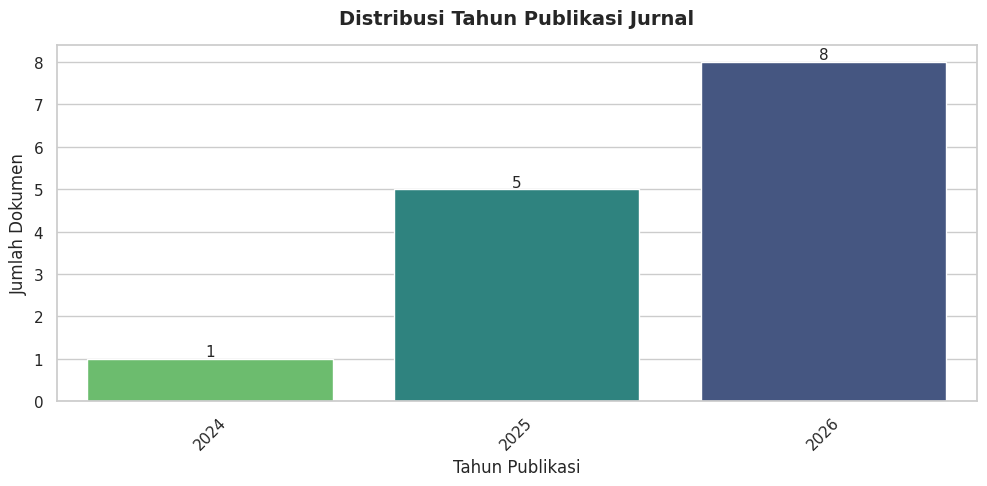


=== 3. EKSTRAKSI KATA KUNCI METODOLOGI (SOTA TRENDS) ===


,Kata Kunci / Metode,Frekuensi
0,llm,24
1,agent,19
2,rag,15
3,knowledge,13
4,graph,10
5,optimization,9
6,hybrid,5
7,embedding,5
8,loss,5
9,reranking,5


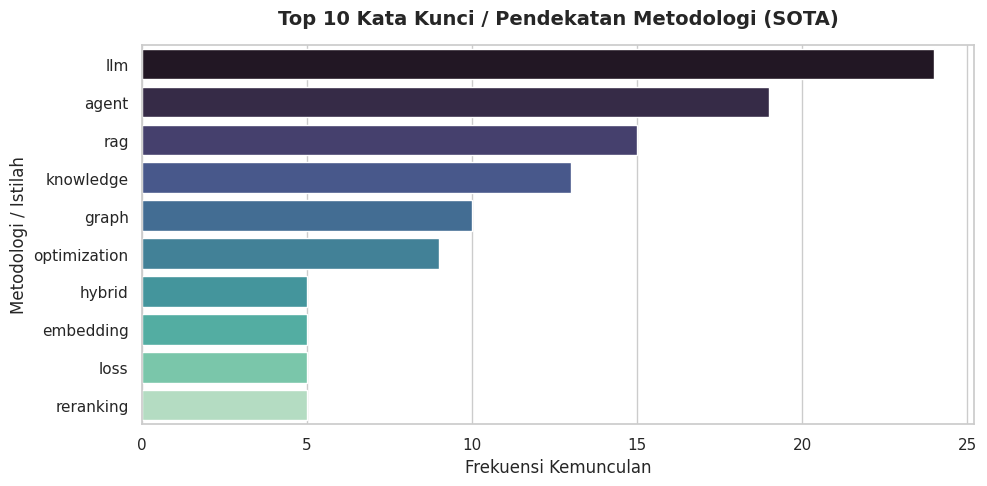

In [11]:
!pip install -q Sastrawi nltk

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re
import nltk
from nltk.corpus import stopwords
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# 1. MENGUNDUH DATASET STOPWORDS NLTK DI BACKGROUND
nltk.download('stopwords', quiet=True)

# 2. MENGATUR GAYA VISUALISASI
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.autolayout': True})

try:
    if 'df_gap_matrix' not in locals() and 'df_gap_matrix' not in globals():
        raise NameError("Variabel df_gap_matrix tidak ditemukan. Pastikan proses ekstraksi (Cell 6) telah dijalankan.")

    print("=== 1. ANALISIS KUALITAS DATA & KELENGKAPAN INFORMASI ===")

    unspecified_terms = {"tidak disebutkan", "not mentioned", "-", "n/a", "tidak ada", "[]", "['']", ""}

    # Fungsi untuk kebal terhadap tipe data List / Array
    def is_missing(val):
        if val is None:
            return True
        # Jika bentuknya list atau dictionary
        if isinstance(val, (list, tuple, dict)):
            if len(val) == 0:
                return True
            val = str(val) # Konversi list ke string untuk pengecekan teks

        # Pengecekan nilai kosong Pandas (NaN) dengan try-except sebagai pengaman ekstra
        try:
            if pd.isna(val):
                return True
        except ValueError:
            pass

        return str(val).strip().lower() in unspecified_terms

    quality_report = []
    total_rows = len(df_gap_matrix)
    for col in df_gap_matrix.columns:
        missing_count = df_gap_matrix[col].apply(is_missing).sum()
        percentage = (missing_count / total_rows) * 100 if total_rows > 0 else 0
        quality_report.append({
            "Kolom": col,
            "Jumlah Kosong/Tidak Disebutkan": missing_count,
            "Persentase (%)": round(percentage, 2)
        })

    df_quality = pd.DataFrame(quality_report).set_index("Kolom")
    display(df_quality)

    print("\n" + "="*50 + "\n")
    print("=== 2. VISUALISASI TREN PUBLIKASI BERDASARKAN TAHUN ===")

    # Menggunakan Regex untuk mengekstrak 4 digit angka tahun dengan aman
    df_plot = df_gap_matrix.copy()

    df_plot['Tahun_Clean'] = df_plot['Tahun'].astype(str).str.extract(r'(\d{4})')
    df_plot = df_plot.dropna(subset=['Tahun_Clean'])

    if not df_plot.empty:
        plt.figure(figsize=(10, 5))
        ax = sns.countplot(
            data=df_plot, x='Tahun_Clean', hue='Tahun_Clean', palette='viridis',
            order=sorted(df_plot['Tahun_Clean'].unique()), legend=False
        )
        plt.title('Distribusi Tahun Publikasi Jurnal', fontsize=14, fontweight='bold', pad=15)
        plt.xlabel('Tahun Publikasi', fontsize=12)
        plt.ylabel('Jumlah Dokumen', fontsize=12)
        plt.xticks(rotation=45)

        for p in ax.patches:
            ax.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 5),
                        textcoords='offset points', fontsize=11)

        plt.tight_layout()

        plt.savefig('/content/Publication_Year_Trends.png', dpi=300)
        plt.show()
    else:
        print("Peringatan: Tidak ada data tahun yang valid untuk divisualisasikan.")

    print("\n=== 3. EKSTRAKSI KATA KUNCI METODOLOGI (SOTA TRENDS) ===")

    # Pastikan data di-flatten jika ada list sebelum di-join
    metodologi_all = " ".join(df_gap_matrix['Metodologi'].dropna().astype(str)).lower()

    # Standardisasi istilah
    replacements = {
        r'retrieval[- ]augmented[- ]generation': 'rag',
        r'large[- ]language[- ]model[s]?': 'llm',
        r'\bllms\b': 'llm',
        r'optimasi': 'optimization',
        r'multi-agent': 'agent',
        r'\bagen\b': 'agent',
        r'\bagentic\b': 'agent',
        r'\bgraf\b': 'graph',
        r'\bpengetahuan\b': 'knowledge',
        r'\bmulti[- ]modal(ity)?\b': 'multimodal',
        r'fine[- ]tuning': 'finetuning',
        r'\bsimulat(ion|e|ed|ing)\b': 'agent',
        r'(re[- ])?rank(ing|er)?': 'reranking',
        r'\bvektor\b': 'vector',
        r'\bgpt(-\d)?\b': 'llm',
        r'\bhibrida\b': 'hybrid'

    }
    for pattern, repl in replacements.items():
        metodologi_all = re.sub(pattern, repl, metodologi_all)

    # Penggunaan NLTK & SASTRAWI
    stopword_indo = set(StopWordRemoverFactory().get_stop_words())
    stopword_inggris = set(stopwords.words('english'))
    domain_stopwords = stopword_indo.union(stopword_inggris)

    # Menambahkan murni hanya kata-kata teknis penelitian
    domain_stopwords.update([
        "metode", "penelitian", "digunakan", "menggunakan", "pendekatan", "sistem",
        "kerangka", "kerja", "pencarian", "model", "method", "framework", "approach",
        "system", "based", "integrasi", "integrated", "ulang", "menggabungkan",
        "source", "sumber", "utama", "mencakup", "review", "automated", "human",
        "module", "validation", "bukti", "tiga", "lingkungan", "verifikasi",
        "terdiri", "entitas", "dua", "dense", "augmented", "analisis", "analysis",
        "into", "combining", "modul", "web", "science", "retrieval", "mengusulkan",
        "data", "multi", "layer", "dilakukan", "across", "tahap", "step",
        "ketidakpastian", "uncertainty", "techniques", "technique", "teknik",
        "ukuran", "informasi", "information", "using", "rantai", "pasok", "supply","chain",
        "studi", "kasus", "case", "study", "selection", "select", "seleksi", "utilizing",
        "utilize", "utilization", "simulation", "simulasi", "simulate", "industrial", "industri",
        "industry", "strategi", "strategy", "strategies", "eksperimen", "experiment", "experiments", "experimental",
        "bereksperimen", "experimentation", "ekperimen", "eksperimental", "conduct", "conducted", "conducting",
        "vary", "varying", "varied", "varies", "various", "size", "ukuran", "search", "searching", "searches",
        "manufacturing", "manufacture", "manufaktur", "manusia", "human", "humans", "humanity", "generasi", "generation",
        "generate", "generated", "generating", "melalui", "menjadi", "basis", "base", "based", "berbasis", "mengintegrasikan",
        "integrasi", "integrate", "integrated", "integrating", "integration"
    ])

    # Tokenisasi dan filtering
    words = re.findall(r'\b[a-z]{3,}\b', metodologi_all)
    filtered_words = [w for w in words if w not in domain_stopwords]

    # Hitung dan Visualisasikan
    word_counts = Counter(filtered_words)
    df_keywords = pd.DataFrame(word_counts.most_common(10), columns=['Kata Kunci / Metode', 'Frekuensi'])

    display(df_keywords)

    if not df_keywords.empty:
        plt.figure(figsize=(10, 5))
        sns.barplot(
            data=df_keywords, x='Frekuensi', y='Kata Kunci / Metode',
            hue='Kata Kunci / Metode', palette='mako', legend=False
        )
        plt.title('Top 10 Kata Kunci / Pendekatan Metodologi (SOTA)', fontsize=14, fontweight='bold', pad=15)
        plt.xlabel('Frekuensi Kemunculan', fontsize=12)
        plt.ylabel('Metodologi / Istilah', fontsize=12)
        plt.savefig('/content/SOTA_Methodology_Trends.png', dpi=300)
        plt.show()

except Exception as e:
    print(f"❌ Terjadi kesalahan saat proses EDA: {e}")

Ekspor Data & Otomatisasi Push ke GitHub via PyGithub API

In [13]:
!pip install -q PyGithub

import os
from github import Github
from github.GithubException import UnknownObjectException
from google.colab import userdata

print("=== 5. EKSPOR HASIL & OTOMATISASI GITHUB (API MODE) ===")

# 1. SIMPAN GAP MATRIX KE MEMORI LOKAL
df_gap_matrix.drop(columns=['Tahun_Clean'], errors='ignore').to_csv('/content/GAP_Matrix_Result.csv', index=False)
print("✅ Tabel Gap Matrix berhasil disimpan ke format CSV.")

try:
# 2. MENGAMBIL TOKEN DARI COLAB SECRETS
    GITHUB_TOKEN = userdata.get('GITHUB_TOKEN')

    # ---------------------------------------------------------
    # UBAH 2 BARIS DI BAWAH INI SESUAI AKUN & REPOSITORY
    GITHUB_USER = "RuthAmalia"
    GITHUB_REPO = "rag_gap_matrix"
    # ---------------------------------------------------------

    print("\nMemulai koneksi ke GitHub API...")
    g = Github(GITHUB_TOKEN)
    repo = g.get_repo(f"{GITHUB_USER}/{GITHUB_REPO}")

# 3. DAFTAR FILE SPESIFIK YANG AKAN DIUNGGAH (mencegah file sampah/terhapus ikut masuk)
    files_to_upload = [
        '/content/GAP_Matrix_Result.csv',
        '/content/Publication_Year_Trends.png',
        '/content/SOTA_Methodology_Trends.png'
    ]

# 4. PROSES UPLOAD/UPDATE) SECARA OTOMATIS DAN STATELESS
    for file_path in files_to_upload:
        # Cek apakah file benar-benar ada di Colab sebelum diunggah
        if not os.path.exists(file_path):
            print(f"⚠️ Melewati: File {file_path} tidak ditemukan di Colab.")
            continue

        file_name = os.path.basename(file_path)

        # Membaca file sebagai binary
        with open(file_path, 'rb') as file:
            content = file.read()

        try:
            # Mengecek apakah file sudah ada di repositori GitHub
            contents = repo.get_contents(file_name)

            # Jika ada, lakukan UPDATE (menimpa file lama)
            repo.update_file(
                path=contents.path,
                message=f"Auto-update: Memperbarui {file_name} dari Google Colab",
                content=content,
                sha=contents.sha
            )
            print(f"🔄 Berhasil menimpa file lama di GitHub: {file_name}")

        except UnknownObjectException:
            # Jika file belum ada, lakukan CREATE (unggah baru)
            repo.create_file(
                path=file_name,
                message=f"Auto-upload: Menambahkan {file_name} dari Google Colab",
                content=content
            )
            print(f"✨ Berhasil mengunggah file baru ke GitHub: {file_name}")

    print("\n🚀 PROSES SELESAI! Semua file riset Anda berhasil disinkronisasi dengan rapi.")

except userdata.SecretNotFoundError:
    print("\n⚠️ GITHUB_TOKEN tidak ditemukan di menu Secrets.")
    print("Silakan tambahkan token terlebih dahulu jika ingin mengotomatisasi push ke GitHub.")
except Exception as e:
    print(f"\n❌ Terjadi kesalahan saat sinkronisasi: {e}")

=== 5. EKSPOR HASIL & OTOMATISASI GITHUB (API MODE) ===
✅ Tabel Gap Matrix berhasil disimpan ke format CSV.

Memulai koneksi ke GitHub API...


/tmp/ipykernel_10859/3670734137.py:26: DeprecationWarning: Argument login_or_token is deprecated, please use auth=github.Auth.Token(...) instead
  g = Github(GITHUB_TOKEN)


🔄 Berhasil menimpa file lama di GitHub: GAP_Matrix_Result.csv
🔄 Berhasil menimpa file lama di GitHub: Publication_Year_Trends.png
🔄 Berhasil menimpa file lama di GitHub: SOTA_Methodology_Trends.png

🚀 PROSES SELESAI! Semua file riset Anda berhasil disinkronisasi dengan rapi.
